# Notebook 3A — Modelagem preditiva das emissões horárias de CO₂

## Carga instantânea × contexto e trajetória operacional

Este notebook dá continuidade ao **Notebook 2 — Tratamento e preparação dos dados**.

### Pergunta experimental

> **Em que medida a inclusão de informações sobre estados, memória e trajetória operacional melhora a estimação das emissões horárias de CO₂ em relação ao uso apenas da carga instantânea?**

### Cenários

**Cenário A — carga instantânea**  
`CO₂(t) = f(P(t))`

**Cenário B — carga + trajetória operacional**  
`CO₂(t) = f(P(t), P(t−1), ΔP, |ΔP|, média 3h, OT(t−1), horas desde startup)`

### Protocolo

- treino: janeiro a setembro de 2025;
- validação: outubro de 2025;
- teste: novembro e dezembro de 2025;
- mesma arquitetura de MLP nos dois cenários;
- métricas: MAE, RMSE e R²;
- análise complementar durante startups e rampas intensas.

O conjunto de teste não participa do ajuste do modelo.

**Atualização bibliográfica de 29/10/2026.** As referências adicionais foram confrontadas com o texto integral fornecido. Elas foram incorporadas onde sustentam diretamente a motivação operacional, a avaliação temporal ou os limites de transferência. Não houve alteração de resultados nem novo treinamento nesta revisão; quando a nova literatura sugere procedimentos não executados, eles são identificados apenas como limites ou possibilidades de validação futura.


## Fundamentação, fontes e decisões do protocolo

As notas metodológicas vinculam as técnicas empregadas às respectivas publicações ou documentações oficiais. As referências completas aparecem ao final deste notebook. As rotinas de leitura, persistência, verificação de integridade e organização dos resultados são implementações do projeto.

**Escolhas do estudo.** A arquitetura, a saída linear, os hiperparâmetros, os períodos de treinamento, validação e teste e os limiares dos contextos operacionais são escolhas experimentais do projeto. A comparação é descritiva, com uma semente por configuração.

**Atualização documental de 24/10/2026.** Foram acrescentadas explicações, citações e referências. As instruções executáveis e as saídas armazenadas foram preservadas. Esta revisão não corresponde a uma nova execução dos experimentos. A rastreabilidade da verificação computacional permanece nos registros de reprodução.

O [guia de fundamentação metodológica](../docs/fundamentacao_metodologica.md) relaciona as fontes, seu alcance e os controles adotados ao longo dos notebooks.


In [1]:
# ============================================================
# CÉLULA 1 — CONFIGURAÇÃO DO AMBIENTE
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Preparar o ambiente necessário para a etapa de modelagem.
#
# Nesta célula:
#
#   1. importamos as bibliotecas;
#   2. definimos uma semente de aleatoriedade;
#   3. configuramos a reprodutibilidade do TensorFlow;
#   4. montamos o Google Drive;
#   5. definimos a estrutura de diretórios do projeto;
#   6. criamos, caso necessário, as pastas de saída;
#   7. definimos os arquivos que serão recebidos dos notebooks
#      anteriores.
#
# Nenhum modelo é treinado nesta etapa.
# ============================================================


# ============================================================
# 1. IMPORTAÇÕES
# ============================================================

from google.colab import drive
from pathlib import Path

import json
import random
import warnings
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from IPython.display import display, Markdown


# ============================================================
# 2. CONFIGURAÇÕES GERAIS
# ============================================================
#
# Os warnings são ocultados para manter a saída do notebook
# mais limpa.
#
# A semente fixa permite reduzir variações entre execuções.
#
# Isso é especialmente importante em redes neurais, pois:
#
#   - inicialização de pesos;
#   - operações internas;
#   - processos pseudoaleatórios
#
# podem produzir pequenas diferenças entre execuções.
# ============================================================

warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)


# ------------------------------------------------------------
# Quando disponível, solicita ao TensorFlow operações
# determinísticas.
#
# O bloco try/except evita interromper o notebook caso o
# ambiente de execução não suporte essa opção.
# ------------------------------------------------------------

try:

    tf.config.experimental.enable_op_determinism()

except Exception:

    pass


# ============================================================
# 3. MONTAR O GOOGLE DRIVE
# ============================================================
#
# Os dados, modelos, tabelas, figuras e relatórios do projeto
# são mantidos de forma persistente no Google Drive.
# ============================================================

drive.mount("/content/drive")


# ============================================================
# 4. ESTRUTURA DE DIRETÓRIOS
# ============================================================

ROOT = Path(
    "/content/drive/MyDrive/co2-cems-thermal-modeling"
)

DATA_PROCESSED = (
    ROOT
    /
    "data"
    /
    "processed"
)

PIPELINE_DIR = (
    ROOT
    /
    "pipeline"
)

OUTPUT = (
    ROOT
    /
    "outputs"
)

REPORTS = (
    OUTPUT
    /
    "reports"
)

FIGURES = (
    OUTPUT
    /
    "figures"
)

TABLES = (
    OUTPUT
    /
    "tables"
)

MODELS = (
    OUTPUT
    /
    "models"
)


# ============================================================
# 5. GARANTIR A EXISTÊNCIA DAS PASTAS DE SAÍDA
# ============================================================
#
# parents=True:
# cria também diretórios superiores, se necessário.
#
# exist_ok=True:
# não gera erro caso a pasta já exista.
# ============================================================

for folder in [
    REPORTS,
    FIGURES,
    TABLES,
    MODELS
]:

    folder.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# 6. ARQUIVOS DE ENTRADA
# ============================================================
#
# selected_unit.json
#     contém a unidade escolhida pelo Notebook 1.
#
# modeling_dataset_operating_hours.parquet
#     contém a base operacional preparada pelo Notebook 2.
# ============================================================

CONFIG_PATH = (
    PIPELINE_DIR
    /
    "selected_unit.json"
)

MODEL_DATA_PATH = (
    DATA_PROCESSED
    /
    "modeling_dataset_operating_hours.parquet"
)


# ============================================================
# 7. CONFIRMAÇÃO DA CONFIGURAÇÃO
# ============================================================

print("=" * 72)

print(
    "NOTEBOOK 3A — MODELAGEM PREDITIVA DE CO₂"
)

print("=" * 72)

print(
    "Diretório do projeto:"
)

print(
    ROOT
)

Mounted at /content/drive
NOTEBOOK 3A — MODELAGEM PREDITIVA DE CO₂
Diretório do projeto:
/content/drive/MyDrive/co2-cems-thermal-modeling


In [2]:
# ============================================================
# CÉLULA 2 — CARREGAMENTO E VERIFICAÇÃO DA INTERFACE
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Recuperar os artefatos produzidos pelos notebooks anteriores
# e verificar se a cadeia de processamento está íntegra.
#
# O Notebook 3A não seleciona novamente a usina e não refaz o
# tratamento dos dados.
#
# Ele recebe:
#
#   Notebook 1 → identidade da unidade
#   Notebook 2 → base preparada para modelagem
#
# Isso mantém o pipeline modular e reprodutível.
# ============================================================


# ============================================================
# 1. VERIFICAR SE OS ARQUIVOS NECESSÁRIOS EXISTEM
# ============================================================
#
# Caso algum arquivo esteja ausente, interrompemos imediatamente
# a execução.
#
# Isso evita continuar a modelagem com uma entrada incompleta
# ou diferente da esperada.
# ============================================================

if not CONFIG_PATH.exists():

    raise FileNotFoundError(
        "selected_unit.json não encontrado. "
        "Execute o Notebook 1."
    )


if not MODEL_DATA_PATH.exists():

    raise FileNotFoundError(

        "modeling_dataset_operating_hours.parquet "
        "não encontrado. "

        "Execute o Notebook 2."
    )


# ============================================================
# 2. CARREGAR A IDENTIFICAÇÃO DA UNIDADE
# ============================================================

with open(
    CONFIG_PATH,
    "r",
    encoding="utf-8"
) as f:

    selected_unit = json.load(f)


# ============================================================
# 3. CARREGAR A BASE OPERACIONAL
# ============================================================
#
# O formato Parquet preserva:
#
#   - tipos das colunas;
#   - estrutura tabular;
#   - armazenamento eficiente.
# ============================================================

model_data = pd.read_parquet(
    MODEL_DATA_PATH
)


# ============================================================
# 4. GARANTIR O FORMATO TEMPORAL DO TIMESTAMP
# ============================================================

model_data["timestamp"] = pd.to_datetime(
    model_data["timestamp"],
    errors="coerce"
)


# ============================================================
# 5. GARANTIR ORDEM CRONOLÓGICA
# ============================================================
#
# Como o problema é temporal, a ordem das observações precisa
# ser preservada durante todo o experimento.
# ============================================================

model_data = (
    model_data
    .sort_values("timestamp")
    .reset_index(drop=True)
)


# ============================================================
# 6. VERIFICAÇÃO DA INTERFACE
# ============================================================

print("=" * 72)
print("INTERFACE ENTRE NOTEBOOKS")
print("=" * 72)

print(
    f"\nUnidade: "
    f"{selected_unit['facility_name']} "
    f"— Unit {selected_unit['unit_id']}"
)

print(
    "Facility ID:",
    selected_unit["facility_id"]
)

print(
    "Ano:",
    selected_unit["year"]
)

print(
    "Observações operacionais:",
    f"{len(model_data):,}"
)

print(
    "Período:",
    model_data["timestamp"].min(),
    "→",
    model_data["timestamp"].max()
)

print(
    "Interface Notebook 2 → Notebook 3A: OK"
)

INTERFACE ENTRE NOTEBOOKS

Unidade: Iatan — Unit 2
Facility ID: 6065
Ano: 2025
Observações operacionais: 6,249
Período: 2025-01-01 16:00:00 → 2025-12-31 23:00:00
Interface Notebook 2 → Notebook 3A: OK


In [3]:
# ============================================================
# CÉLULA 3 — AUDITORIA E DEFINIÇÃO DOS CENÁRIOS
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Definir formalmente:
#
#   - variável-alvo;
#   - features do Cenário A;
#   - features do Cenário B;
#
# e verificar se todas as colunas necessárias estão presentes.
#
#
# PERGUNTA EXPERIMENTAL
# ------------------------------------------------------------
#
# Cenário A:
#
#       CO₂(t) = f(P(t))
#
# utiliza somente a carga atual.
#
#
# Cenário B:
#
# utiliza carga atual + informações sobre memória e trajetória.
#
#
# IMPORTANTE
# ------------------------------------------------------------
# Nenhuma feature derivada do CO₂ é utilizada como entrada.
#
# Portanto, evitamos TARGET LEAKAGE.
# ============================================================

# ============================================================
# FUNDAMENTAÇÃO METODOLÓGICA — APRENDIZADO SUPERVISIONADO E COMPARAÇÃO DE FEATURES
# ------------------------------------------------------------
# Problema de IA/ML: APRENDIZADO SUPERVISIONADO PARA REGRESSÃO.
# O alvo Y é a massa horária de CO2, variável numérica contínua.
# As entradas X são observações de carga e contexto operacional.
# O Cenário A é o baseline com P(t); o B acrescenta trajetória.
# Esta é uma controlled feature-set comparison, comparação
# controlada de conjuntos de variáveis com lógica de ablação
# aditiva (feature-ablation logic), não uma ablação por remoção
# clássica. Não afirmamos equivalência entre números de pesos.
# A arquitetura oculta e o protocolo de treinamento são comuns.
# ============================================================




# ============================================================
# 1. VARIÁVEL-ALVO
# ============================================================

TARGET = "CO2 Mass (short tons)"


# ============================================================
# 2. CENÁRIO A — SOMENTE CARGA INSTANTÂNEA
# ============================================================

FEATURES_A = [

    "load_current_mw"

]


# ============================================================
# 3. CENÁRIO B — CARGA + TRAJETÓRIA OPERACIONAL
# ============================================================

FEATURES_B = [

    "load_current_mw",

    "load_lag_1h",

    "delta_load_1h",

    "abs_delta_load_1h",

    "load_mean_previous_3h",

    "operating_time_lag_1h",

    "hours_since_startup"

]


# ============================================================
# 4. LISTAR TODAS AS COLUNAS NECESSÁRIAS
# ============================================================
#
# set() elimina repetições.
#
# sorted() apenas organiza a lista para facilitar auditoria.
# ============================================================

required_columns = (

    ["timestamp", TARGET]

    +

    sorted(
        set(
            FEATURES_A
            +
            FEATURES_B
        )
    )

)


# ============================================================
# 5. VERIFICAR SE EXISTEM COLUNAS AUSENTES
# ============================================================

missing_columns = [

    column

    for column in required_columns

    if column not in model_data.columns

]


if missing_columns:

    raise ValueError(
        f"Colunas necessárias ausentes: {missing_columns}"
    )


# ============================================================
# 6. AUDITORIA DAS FEATURES
# ============================================================
#
# A tabela permite conferir:
#
#   - nome da variável;
#   - tipo;
#   - quantidade de dados ausentes.
# ============================================================

feature_audit = pd.DataFrame({

    "variavel":
        required_columns,

    "tipo":
        [
            str(
                model_data[column].dtype
            )
            for column in required_columns
        ],

    "ausentes":
        [
            int(
                model_data[column]
                .isna()
                .sum()
            )
            for column in required_columns
        ]

})


display(
    feature_audit
)


# ============================================================
# 7. CONSTRUIR BASE EXPERIMENTAL
# ============================================================
#
# Mantemos somente as colunas necessárias.
#
# dropna():
# exclui eventual observação que não tenha todas as informações
# necessárias ao experimento.
#
# A ordem temporal é novamente garantida.
# ============================================================

experiment_data = (

    model_data[
        required_columns
    ]

    .dropna()

    .sort_values(
        "timestamp"
    )

    .reset_index(
        drop=True
    )

)


# ============================================================
# 8. RESUMIR OS DOIS CENÁRIOS
# ============================================================

scenario_table = pd.DataFrame({

    "cenario": [

        "A — carga instantânea",

        "B — carga + trajetória"

    ],

    "n_features": [

        len(FEATURES_A),

        len(FEATURES_B)

    ],

    "features": [

        ", ".join(FEATURES_A),

        ", ".join(FEATURES_B)

    ]

})


display(
    scenario_table
)


print(
    "Observações válidas para o experimento:",
    f"{len(experiment_data):,}"
)

print(
    "Variável-alvo:",
    TARGET
)

,variavel,tipo,ausentes
0,timestamp,datetime64[ns],0
1,CO2 Mass (short tons),float64,0
2,abs_delta_load_1h,float64,0
3,delta_load_1h,float64,0
4,hours_since_startup,int64,0
5,load_current_mw,float64,0
6,load_lag_1h,float64,0
7,load_mean_previous_3h,float64,0
8,operating_time_lag_1h,float64,0


,cenario,n_features,features
0,A — carga instantânea,1,load_current_mw
1,B — carga + trajetória,7,"load_current_mw, load_lag_1h, delta_load_1h, a..."


Observações válidas para o experimento: 6,249
Variável-alvo: CO2 Mass (short tons)


### Fundamentação da avaliação temporal

A avaliação de modelos para séries temporais precisa considerar a ordem das observações e o procedimento de estimação do desempenho (Cerqueira; Torgo; Mozetič, 2020). Neste estudo, as datas das partições e o calendário das validações são decisões do protocolo. O teste permanece fora do ajuste de cada comparação, mas seu uso reiterado no desenvolvimento limita a independência da avaliação em relação às decisões da pesquisa (Cawley; Talbot, 2010). A divisão cronológica, isoladamente, não elimina esse limite.


In [4]:
# Referências metodológicas: (Cerqueira; Torgo; Mozetič, 2020; Cawley; Talbot, 2010).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
# CÉLULA 4 — DIVISÃO TEMPORAL
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Separar os dados em treino, validação e teste preservando
# completamente a ordem cronológica.
#
#
# POR QUE NÃO USAR UMA DIVISÃO ALEATÓRIA?
# ------------------------------------------------------------
# Como os dados formam uma série temporal, sortear observações
# poderia colocar informações futuras no conjunto utilizado para
# construir um modelo destinado a prever o passado.
#
# O protocolo adotado é:
#
#   TREINO:
#       janeiro → setembro
#
#   VALIDAÇÃO:
#       outubro
#
#   TESTE:
#       novembro → dezembro
#
#
# O teste permanece isolado até a avaliação final.
# ============================================================

# ============================================================
# FUNDAMENTAÇÃO METODOLÓGICA — TEMPORAL HOLDOUT
# ------------------------------------------------------------
# Nome canônico: temporal holdout (partição cronológica fixa).
# Treino: meses iniciais; validação: mês seguinte; teste: final.
# A validação orienta o EarlyStopping; o teste é usado somente
# na avaliação final fora da amostra (out-of-sample evaluation).
# Não se trata de random split nem de cross-validation.
# A ordem temporal reduz o risco de vazamento do futuro.
# ============================================================




# ============================================================
# 1. DEFINIR OS LIMITES TEMPORAIS
# ============================================================

YEAR = int(
    selected_unit["year"]
)

TRAIN_END = pd.Timestamp(
    f"{YEAR}-09-30 23:00:00"
)

VALIDATION_END = pd.Timestamp(
    f"{YEAR}-10-31 23:00:00"
)


# ============================================================
# 2. CONJUNTO DE TREINO
# ============================================================

train_data = (

    experiment_data[
        experiment_data["timestamp"]
        <=
        TRAIN_END
    ]

    .copy()

)


# ============================================================
# 3. CONJUNTO DE VALIDAÇÃO
# ============================================================

validation_data = (

    experiment_data[
        (
            experiment_data["timestamp"]
            >
            TRAIN_END
        )
        &
        (
            experiment_data["timestamp"]
            <=
            VALIDATION_END
        )
    ]

    .copy()

)


# ============================================================
# 4. CONJUNTO DE TESTE
# ============================================================

test_data = (

    experiment_data[
        experiment_data["timestamp"]
        >
        VALIDATION_END
    ]

    .copy()

)


# ============================================================
# 5. RESUMO DA DIVISÃO
# ============================================================

split_summary = pd.DataFrame({

    "conjunto": [
        "Treino",
        "Validação",
        "Teste"
    ],

    "inicio": [
        train_data["timestamp"].min(),
        validation_data["timestamp"].min(),
        test_data["timestamp"].min()
    ],

    "fim": [
        train_data["timestamp"].max(),
        validation_data["timestamp"].max(),
        test_data["timestamp"].max()
    ],

    "observacoes": [
        len(train_data),
        len(validation_data),
        len(test_data)
    ]

})


# Percentual de cada conjunto dentro da base experimental.

split_summary[
    "percentual"
] = (

    100

    *

    split_summary["observacoes"]

    /

    len(experiment_data)

)


display(
    split_summary.round(2)
)


# ============================================================
# 6. SALVAR A DIVISÃO TEMPORAL
# ============================================================
#
# Essa tabela documenta exatamente quais períodos foram
# utilizados no experimento.
# ============================================================

SPLIT_TABLE_PATH = (
    TABLES
    /
    "03A_divisao_temporal.csv"
)

split_summary.to_csv(
    SPLIT_TABLE_PATH,
    index=False
)

print(
    "Tabela salva em:",
    SPLIT_TABLE_PATH
)

,conjunto,inicio,fim,observacoes,percentual
0,Treino,2025-01-01 16:00:00,2025-09-30 23:00:00,4894,78.32
1,Validação,2025-10-01 00:00:00,2025-10-31 23:00:00,211,3.38
2,Teste,2025-11-01 00:00:00,2025-12-31 23:00:00,1144,18.31


Tabela salva em: /content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A_divisao_temporal.csv


### Fonte da normalização e prevenção de vazamento

A transformação MinMax e a distinção entre ajustar no treino e apenas transformar os outros conjuntos seguem a documentação da biblioteca (Scikit-learn, 2025). Os extremos são estimados somente no treinamento da partição correspondente. O código mantém esse ajuste para validação e teste; quando o alvo é normalizado, a transformação é revertida antes da avaliação em sua unidade original. Essa precaução não substitui a auditoria das demais fontes possíveis de vazamento.


In [5]:
# Referências metodológicas: (Scikit-learn, 2025).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
# CÉLULA 5 — NORMALIZAÇÃO MIN–MAX
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Colocar as variáveis em escalas comparáveis antes do
# treinamento da rede neural.
#
#
# POR QUE NORMALIZAR?
# ------------------------------------------------------------
# As features possuem amplitudes e unidades diferentes.
#
# Exemplo:
#
#   carga               → centenas de MW
#   Operating Time      → aproximadamente 0 a 1
#   horas desde startup → dezenas ou centenas de horas
#
# Redes neurais normalmente apresentam treinamento mais estável
# quando as entradas estão em escalas semelhantes.
#
#
# REGRA CONTRA DATA LEAKAGE
# ------------------------------------------------------------
# O scaler é AJUSTADO SOMENTE NO TREINO.
#
# Validação e teste utilizam os parâmetros aprendidos no treino.
#
# Assim:
#
#   fit_transform → somente treino
#   transform     → validação e teste
# ============================================================

# ============================================================
# FUNDAMENTAÇÃO METODOLÓGICA — TRAIN-ONLY MIN-MAX SCALING
# ------------------------------------------------------------
# Técnica: min-max feature scaling (normalização por amplitude).
# Cada scaler aprende mínimo e máximo apenas no TREINAMENTO.
# Em validação/teste aplicamos transform(), nunca fit().
# Isso evita data leakage durante o pré-processamento.
# Valores futuros fora do intervalo do treino podem produzir
# resultados transformados abaixo de 0 ou acima de 1.
# O alvo y recebe scaler próprio, revertido antes das métricas.
# ============================================================




# ============================================================
# 1. MATRIZES DE ENTRADA — CENÁRIO A
# ============================================================

X_train_A = (
    train_data[
        FEATURES_A
    ]
    .copy()
)

X_validation_A = (
    validation_data[
        FEATURES_A
    ]
    .copy()
)

X_test_A = (
    test_data[
        FEATURES_A
    ]
    .copy()
)


# ============================================================
# 2. MATRIZES DE ENTRADA — CENÁRIO B
# ============================================================

X_train_B = (
    train_data[
        FEATURES_B
    ]
    .copy()
)

X_validation_B = (
    validation_data[
        FEATURES_B
    ]
    .copy()
)

X_test_B = (
    test_data[
        FEATURES_B
    ]
    .copy()
)


# ============================================================
# 3. VARIÁVEL-ALVO
# ============================================================

y_train = (
    train_data[
        [TARGET]
    ]
    .copy()
)

y_validation = (
    validation_data[
        [TARGET]
    ]
    .copy()
)

y_test = (
    test_data[
        [TARGET]
    ]
    .copy()
)


# ============================================================
# 4. CRIAR OS SCALERS
# ============================================================
#
# A e B possuem conjuntos de features diferentes.
#
# Por isso cada cenário recebe seu próprio scaler X.
#
# O alvo é o mesmo, então existe apenas um scaler y.
# ============================================================

scaler_X_A = MinMaxScaler()

scaler_X_B = MinMaxScaler()

scaler_y = MinMaxScaler()


# ============================================================
# 5. AJUSTAR COM TREINO E TRANSFORMAR OS DEMAIS CONJUNTOS
# ============================================================

X_train_A_scaled = (
    scaler_X_A
    .fit_transform(
        X_train_A
    )
)

X_validation_A_scaled = (
    scaler_X_A
    .transform(
        X_validation_A
    )
)

X_test_A_scaled = (
    scaler_X_A
    .transform(
        X_test_A
    )
)


X_train_B_scaled = (
    scaler_X_B
    .fit_transform(
        X_train_B
    )
)

X_validation_B_scaled = (
    scaler_X_B
    .transform(
        X_validation_B
    )
)

X_test_B_scaled = (
    scaler_X_B
    .transform(
        X_test_B
    )
)


# ============================================================
# 6. NORMALIZAR O ALVO
# ============================================================
#
# ravel() transforma o resultado de:
#
#       (n, 1)
#
# para:
#
#       (n,)
#
# formato aceito pela rede neste experimento.
# ============================================================

y_train_scaled = (
    scaler_y
    .fit_transform(
        y_train
    )
    .ravel()
)

y_validation_scaled = (
    scaler_y
    .transform(
        y_validation
    )
    .ravel()
)


# ============================================================
# 7. CONFERIR AS DIMENSÕES
# ============================================================

normalization_summary = pd.DataFrame({

    "conjunto": [

        "Treino A",
        "Validação A",
        "Teste A",

        "Treino B",
        "Validação B",
        "Teste B"

    ],

    "shape": [

        str(X_train_A_scaled.shape),
        str(X_validation_A_scaled.shape),
        str(X_test_A_scaled.shape),

        str(X_train_B_scaled.shape),
        str(X_validation_B_scaled.shape),
        str(X_test_B_scaled.shape)

    ]

})


display(
    normalization_summary
)


print(
    "Scalers ajustados exclusivamente com dados de treino."
)

,conjunto,shape
0,Treino A,"(4894, 1)"
1,Validação A,"(211, 1)"
2,Teste A,"(1144, 1)"
3,Treino B,"(4894, 7)"
4,Validação B,"(211, 7)"
5,Teste B,"(1144, 7)"


Scalers ajustados exclusivamente com dados de treino.


### Fundamentação da técnica de IA utilizada no Notebook 3A

Neste experimento, o objetivo é **prever uma variável numérica contínua**, a massa horária de CO₂, a partir de amostras históricas com entradas conhecidas. Portanto, o problema é de **aprendizado supervisionado para regressão** (*supervised regression*).

**Hierarquia conceitual:** Inteligência Artificial → Machine Learning → Aprendizado Supervisionado → Regressão → Rede Neural Artificial (ANN) → Rede Neural Feedforward → **Multilayer Perceptron (MLP)**.

- **MLP (Perceptron Multicamadas):** rede com camadas densas cujas informações avançam das entradas à saída (*feedforward*), sem conexões recorrentes explícitas. Os atributos de trajetória entram como variáveis já construídas, não como memória recorrente da arquitetura.
- **Dense:** camada de neurônios totalmente conectados, com pesos e termos de viés ajustáveis.
- **ReLU:** função de ativação das camadas ocultas que permite aprender relações não lineares.
- **Saída linear:** fornece uma estimativa contínua de CO₂, apropriada à regressão.
- **MSE (*Mean Squared Error*):** função de perda que quantifica o erro quadrático médio no treinamento.
- **Backpropagation (*retropropagação do erro*):** mecanismo de cálculo dos gradientes que o TensorFlow/Keras executa internamente. Não existe uma implementação manual de retropropagação neste notebook.
- **Adam (*Adaptive Moment Estimation*):** algoritmo de otimização que usa os gradientes para atualizar pesos e vieses.
- **EarlyStopping:** monitora a perda de validação, interrompe o ajuste após falta de progresso e restaura os melhores pesos observados.

**Desenho experimental:** os cenários A e B constituem uma **comparação controlada de conjuntos de variáveis** (*controlled feature-set comparison*), com lógica de ablação aditiva: A usa a carga instantânea e B acrescenta trajetória operacional. A estrutura das camadas ocultas, o otimizador, os hiperparâmetros e os intervalos temporais são compartilhados. A camada de entrada, e portanto a contagem total de parâmetros, não é idêntica entre cenários.

**Avaliação temporal:** a partição cronológica fixa em treino, validação e teste denomina-se **temporal holdout**. Os parâmetros da normalização Min–Max são aprendidos somente no treino, e o período de teste é reservado para avaliação final fora da amostra.

> **Limite da interpretação:** o experimento identifica diferenças preditivas entre A e B no conjunto de teste; não prova causalidade nem executa validação *walk-forward* ou otimização de hiperparâmetros.


### Fontes da rede neural e do treinamento

A retropropagação em redes com camadas intermediárias é fundamentada por Rumelhart, Hinton e Williams (1986). O uso de unidades retificadas é discutido por Glorot, Bordes e Bengio (2011), e o otimizador Adam por Kingma e Ba (2015). Esses trabalhos fundamentam as técnicas. O número de camadas e unidades, a saída linear, a semente, os critérios de parada e os demais hiperparâmetros são configurações do presente experimento. A implementação usa as bibliotecas declaradas no código, sem reimplementar manualmente a retropropagação.


In [6]:
# Referências metodológicas: (Rumelhart; Hinton; Williams, 1986; Glorot; Bordes; Bengio, 2011; Kingma; Ba, 2015).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
# CÉLULA 6 — DEFINIÇÃO DA MLP
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Definir uma única arquitetura de rede neural que será usada
# nos dois cenários.
#
#
# CONTROLE EXPERIMENTAL
# ------------------------------------------------------------
# A arquitetura é mantida igual em A e B.
#
# Assim, a comparação não será:
#
#   modelo simples × modelo complexo
#
# mas:
#
#   MESMO MODELO
#       +
#   INFORMAÇÕES DIFERENTES
#
# Isso permite investigar o valor adicional das informações de
# trajetória operacional.
#
#
# ARQUITETURA
# ------------------------------------------------------------
#
# Entrada
#   ↓
# Dense 64 — ReLU
#   ↓
# Dense 32 — ReLU
#   ↓
# Dense 1 — Linear
#
#
# Como o problema é regressão, a última camada possui:
#
#   1 neurônio
#   ativação linear
# ============================================================

# ============================================================
# FUNDAMENTAÇÃO METODOLÓGICA — MLP, FEEDFORWARD ANN E BACKPROPAGATION
# ------------------------------------------------------------
# TAXONOMIA DA TÉCNICA:
# Inteligência artificial > machine learning > aprendizado
# supervisionado > regressão > rede neural artificial (ANN)
# > feedforward neural network > multilayer perceptron (MLP).
#
# A MLP tem conexões densas e fluxo direto (feedforward).
# ReLU introduz não linearidade nas camadas ocultas;
# a camada de saída usa ativação linear para prever CO2 contínuo.
#
# TREINAMENTO: o TensorFlow/Keras calcula os gradientes por
# retropropagação do erro (backpropagation) internamente.
# O otimizador Adam atualiza os parâmetros a partir deles.
# A função de perda MSE é minimizada no treinamento.
# EarlyStopping monitora MSE de validação (val_loss) e
# restore_best_weights recupera os pesos da melhor época.
# Não implementamos backpropagation manualmente.
# ============================================================




# ============================================================
# 1. HIPERPARÂMETROS FIXOS
# ============================================================

LEARNING_RATE = 1e-3

BATCH_SIZE = 64

MAX_EPOCHS = 500

PATIENCE = 30


# ============================================================
# 2. FUNÇÃO PARA CONSTRUIR A REDE
# ============================================================

def build_mlp(
    n_features,
    seed=SEED
):

    # Mantemos a mesma semente antes da criação de cada modelo.
    tf.keras.utils.set_random_seed(
        seed
    )


    model = keras.Sequential([

        # Camada de entrada.
        #
        # O número de entradas varia conforme o cenário:
        #
        # A → 1 feature
        # B → 7 features

        layers.Input(
            shape=(n_features,)
        ),


        # Primeira camada oculta.

        layers.Dense(
            64,
            activation="relu"
        ),


        # Segunda camada oculta.

        layers.Dense(
            32,
            activation="relu"
        ),


        # Saída da regressão.

        layers.Dense(
            1,
            activation="linear"
        )

    ])


    # --------------------------------------------------------
    # Compilação
    # --------------------------------------------------------
    #
    # Adam:
    # algoritmo de otimização dos pesos.
    #
    # MSE:
    # erro quadrático médio utilizado como função de perda.
    # --------------------------------------------------------

    model.compile(

        optimizer=keras.optimizers.Adam(
            learning_rate=LEARNING_RATE
        ),

        loss="mse"

    )


    return model


# ============================================================
# 3. FUNÇÃO DE TREINAMENTO
# ============================================================

def train_model(
    X_train,
    y_train,
    X_val,
    y_val,
    n_features
):

    # Cria uma nova MLP com a arquitetura padronizada.

    model = build_mlp(
        n_features
    )


    # --------------------------------------------------------
    # EarlyStopping
    # --------------------------------------------------------
    #
    # Monitora o erro de validação.
    #
    # Caso ele deixe de melhorar durante PATIENCE épocas, o
    # treinamento é encerrado.
    #
    # restore_best_weights=True:
    # retorna os pesos da melhor época, e não necessariamente
    # os da última época executada.
    # --------------------------------------------------------

    early_stopping = (
        keras.callbacks.EarlyStopping(

            monitor="val_loss",

            patience=PATIENCE,

            min_delta=1e-6,

            restore_best_weights=True

        )
    )


    # --------------------------------------------------------
    # Treinamento
    # --------------------------------------------------------
    #
    # shuffle=False:
    # preserva a ordem temporal das observações.
    #
    # verbose=0:
    # evita imprimir uma linha para cada época.
    # --------------------------------------------------------

    history = model.fit(

        X_train,
        y_train,

        validation_data=(
            X_val,
            y_val
        ),

        epochs=MAX_EPOCHS,

        batch_size=BATCH_SIZE,

        shuffle=False,

        callbacks=[
            early_stopping
        ],

        verbose=0

    )


    return (
        model,
        history
    )


# ============================================================
# 4. EXIBIR AS DUAS ARQUITETURAS
# ============================================================
#
# As camadas ocultas são iguais.
#
# O número de parâmetros muda apenas porque B possui mais
# variáveis de entrada.
# ============================================================

print(
    "Cenário A"
)

build_mlp(
    len(FEATURES_A)
).summary()


print(
    "Cenário B"
)

build_mlp(
    len(FEATURES_B)
).summary()

Cenário A


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,241 (8.75 KB)

 Trainable params: 2,241 (8.75 KB)

...

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 64)             │           512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,625 (10.25 KB)

 Trainable params: 2,625 (10.25 KB)

 Non-trainable params: 0 (0.00 B)

In [7]:
# ============================================================
# CÉLULA 7 — TREINAMENTO DOS DOIS CENÁRIOS
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Treinar separadamente:
#
#   Modelo A → carga instantânea
#   Modelo B → carga + trajetória
#
# utilizando exatamente o mesmo protocolo.
#
# O conjunto de TESTE continua sem ser utilizado nesta etapa.
# ============================================================

# ============================================================
# FUNDAMENTAÇÃO METODOLÓGICA — DESENHO EXPERIMENTAL CONTROLADO
# ------------------------------------------------------------
# Os dois cenários usam a mesma arquitetura de camadas ocultas,
# seed, critério MSE, Adam, batch size e regra de EarlyStopping.
# A comparação investiga o valor incremental das features.
# É uma controlled feature-set comparison (lógica de ablação),
# com o mesmo recorte de treino, validação e teste.
# A quantidade total de parâmetros difere porque B tem mais
# variáveis na camada de entrada; não se afirma igualdade do
# número de pesos ou prova causal do efeito das features.
# ============================================================




# ============================================================
# 1. TREINAR CENÁRIO A
# ============================================================

print(
    "Treinando Cenário A..."
)

model_A, history_A = train_model(

    X_train_A_scaled,
    y_train_scaled,

    X_validation_A_scaled,
    y_validation_scaled,

    len(FEATURES_A)

)


# ============================================================
# 2. TREINAR CENÁRIO B
# ============================================================

print(
    "Treinando Cenário B..."
)

model_B, history_B = train_model(

    X_train_B_scaled,
    y_train_scaled,

    X_validation_B_scaled,
    y_validation_scaled,

    len(FEATURES_B)

)


# ============================================================
# 3. IDENTIFICAR A MELHOR ÉPOCA DE CADA MODELO
# ============================================================
#
# history.history["val_loss"]:
# contém o erro de validação de cada época.
#
# np.argmin():
# encontra a posição do menor erro.
#
# Somamos 1 porque os índices Python começam em zero, enquanto
# as épocas são apresentadas começando em 1.
# ============================================================

best_epoch_A = int(

    np.argmin(
        history_A.history["val_loss"]
    )

    + 1
)

best_epoch_B = int(

    np.argmin(
        history_B.history["val_loss"]
    )

    + 1
)


# ============================================================
# 4. RESUMO
# ============================================================

print(
    "Melhor época — Cenário A:",
    best_epoch_A
)

print(
    "Melhor época — Cenário B:",
    best_epoch_B
)

print(
    "Parâmetros treináveis — Cenário A:",
    model_A.count_params()
)

print(
    "Parâmetros treináveis — Cenário B:",
    model_B.count_params()
)

Treinando Cenário A...
Treinando Cenário B...
Melhor época — Cenário A: 24
Melhor época — Cenário B: 38
Parâmetros treináveis — Cenário A: 2241
Parâmetros treináveis — Cenário B: 2625


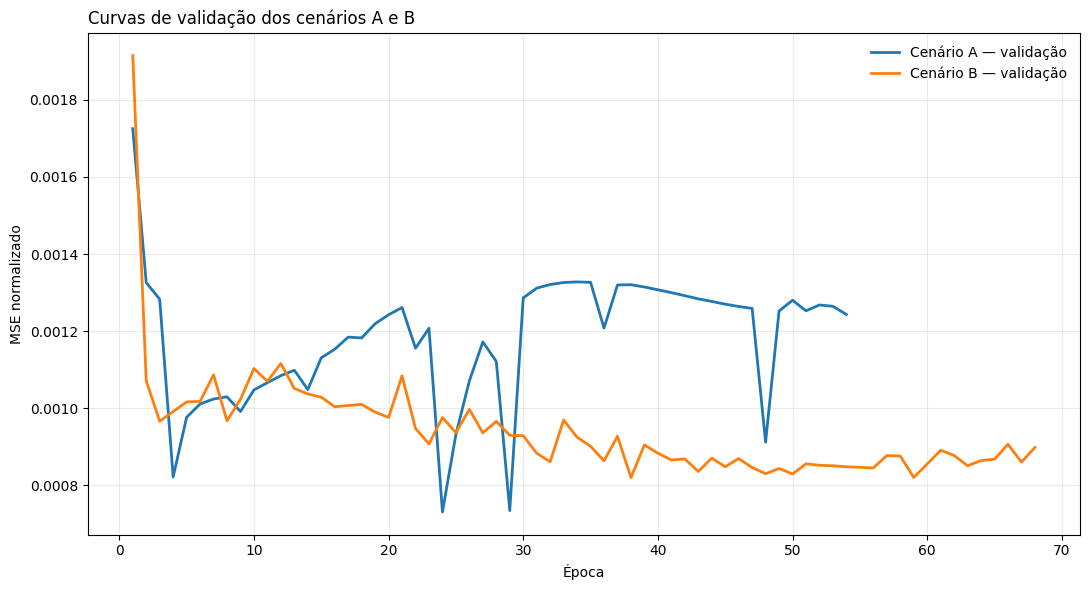

Figura salva em: /content/drive/MyDrive/co2-cems-thermal-modeling/outputs/figures/03A_curvas_validacao.png


In [8]:
# ============================================================
# CÉLULA 8 — CURVAS DE VALIDAÇÃO
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Visualizar como o erro de validação evoluiu ao longo das
# épocas nos dois cenários.
#
# Essa análise ajuda a observar:
#
#   - convergência do treinamento;
#   - estabilidade;
#   - momento em que o modelo deixa de melhorar;
#   - diferenças de comportamento entre A e B.
#
# A curva mostrada é a val_loss, ou seja, MSE calculado no
# conjunto de validação normalizado.
# ============================================================

# ============================================================
# FUNDAMENTAÇÃO METODOLÓGICA — VALIDATION LOSS E EARLY STOPPING
# ------------------------------------------------------------
# A curva val_loss registra o MSE de validação por época,
# calculado na escala normalizada do alvo.
# Early stopping seleciona a época com melhor desempenho de
# validação e encerra treino após ausência de melhora.
# As métricas de teste, em unidades físicas, vêm na CÉLULA 9.
# ============================================================




# ============================================================
# 1. TRANSFORMAR HISTÓRICOS EM DATAFRAMES
# ============================================================

history_A_df = pd.DataFrame(
    history_A.history
)

history_B_df = pd.DataFrame(
    history_B.history
)


# ============================================================
# 2. CONSTRUIR FIGURA
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 6)
)


# Erro de validação do Cenário A.

ax.plot(

    history_A_df.index + 1,

    history_A_df["val_loss"],

    label="Cenário A — validação",

    linewidth=2

)


# Erro de validação do Cenário B.

ax.plot(

    history_B_df.index + 1,

    history_B_df["val_loss"],

    label="Cenário B — validação",

    linewidth=2

)


# ============================================================
# 3. FORMATAÇÃO
# ============================================================

ax.set_title(
    "Curvas de validação dos cenários A e B",
    loc="left"
)

ax.set_xlabel(
    "Época"
)

ax.set_ylabel(
    "MSE normalizado"
)

ax.grid(
    alpha=0.25
)

ax.legend(
    frameon=False
)

fig.tight_layout()


# ============================================================
# 4. SALVAR FIGURA
# ============================================================

LEARNING_CURVE_PATH = (
    FIGURES
    /
    "03A_curvas_validacao.png"
)

fig.savefig(
    LEARNING_CURVE_PATH,
    dpi=220,
    bbox_inches="tight"
)

plt.show()


print(
    "Figura salva em:",
    LEARNING_CURVE_PATH
)

### Definições e alcance das métricas

MAE e RMSE pertencem às medidas usuais de magnitude do erro discutidas por Hyndman e Koehler (2006). As funções de regressão da biblioteca, incluindo R², estão documentadas no guia da biblioteca (Scikit-learn, 2025). As métricas são calculadas sobre as mesmas observações usadas na comparação indicada em cada etapa. A análise dos pares é descritiva e não equivale a um teste de significância.


In [9]:
# Referências metodológicas: (Hyndman; Koehler, 2006; Scikit-learn, 2025).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
# CÉLULA 9 — MÉTRICAS NO CONJUNTO DE TESTE
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Avaliar finalmente os modelos em dados que não participaram
# do treinamento nem da escolha da melhor época.
#
#
# MÉTRICAS
# ------------------------------------------------------------
#
# MAE:
# erro absoluto médio.
#
# RMSE:
# raiz do erro quadrático médio.
# Penaliza mais fortemente erros grandes.
#
# R²:
# proporção da variabilidade do alvo explicada pelo modelo.
#
#
# IMPORTANTE
# ------------------------------------------------------------
# As previsões são realizadas na escala normalizada, mas antes
# das métricas retornamos para:
#
#       CO₂ Mass [short tons]
#
# Portanto, MAE e RMSE permanecem fisicamente interpretáveis.
# ============================================================

# ============================================================
# FUNDAMENTAÇÃO METODOLÓGICA — AVALIAÇÃO FINAL OUT-OF-SAMPLE
# ------------------------------------------------------------
# As métricas no conjunto de teste são um temporal holdout
# fora da amostra, sem participação no ajuste dos modelos.
# A inversão do scaler_y devolve os valores à escala original
# antes de calcular MAE, RMSE e R2.
# ============================================================




# ============================================================
# 1. FUNÇÃO PARA DESNORMALIZAR O ALVO
# ============================================================

def inverse_target(
    values
):

    return (
        scaler_y
        .inverse_transform(
            np.asarray(
                values
            )
            .reshape(-1, 1)
        )
        .ravel()
    )


# ============================================================
# 2. FUNÇÃO DE CÁLCULO DAS MÉTRICAS
# ============================================================

def regression_metrics(
    y_true,
    y_pred
):

    return {

        "MAE":
            mean_absolute_error(
                y_true,
                y_pred
            ),

        "RMSE":
            np.sqrt(
                mean_squared_error(
                    y_true,
                    y_pred
                )
            ),

        "R2":
            r2_score(
                y_true,
                y_pred
            )

    }


# ============================================================
# 3. PREVISÕES DO CENÁRIO A
# ============================================================

pred_A = inverse_target(

    model_A.predict(
        X_test_A_scaled,
        verbose=0
    )
    .ravel()

)


# ============================================================
# 4. PREVISÕES DO CENÁRIO B
# ============================================================

pred_B = inverse_target(

    model_B.predict(
        X_test_B_scaled,
        verbose=0
    )
    .ravel()

)


# ============================================================
# 5. VALORES REAIS
# ============================================================

y_true = (
    y_test[
        TARGET
    ]
    .to_numpy()
)


# ============================================================
# 6. CALCULAR MÉTRICAS
# ============================================================

metrics_A = regression_metrics(
    y_true,
    pred_A
)

metrics_B = regression_metrics(
    y_true,
    pred_B
)


# ============================================================
# 7. TABELA COMPARATIVA
# ============================================================

results = pd.DataFrame([

    {

        "cenario":
            "A — carga instantânea",

        "n_features":
            len(FEATURES_A),

        **metrics_A

    },

    {

        "cenario":
            "B — carga + trajetória",

        "n_features":
            len(FEATURES_B),

        **metrics_B

    }

])


display(
    results.round(4)
)


# ============================================================
# 8. QUANTIFICAR O GANHO DO CENÁRIO B
# ============================================================
#
# Valores positivos em MAE/RMSE indicam redução do erro.
# ============================================================

mae_gain = (

    100

    *

    (
        metrics_A["MAE"]
        -
        metrics_B["MAE"]
    )

    /

    metrics_A["MAE"]

)


rmse_gain = (

    100

    *

    (
        metrics_A["RMSE"]
        -
        metrics_B["RMSE"]
    )

    /

    metrics_A["RMSE"]

)


delta_r2 = (

    metrics_B["R2"]
    -
    metrics_A["R2"]

)


print(
    f"Redução de MAE A → B: "
    f"{mae_gain:+.2f}%"
)

print(
    f"Redução de RMSE A → B: "
    f"{rmse_gain:+.2f}%"
)

print(
    f"Variação de R² A → B: "
    f"{delta_r2:+.4f}"
)


# ============================================================
# 9. SALVAR RESULTADOS
# ============================================================

RESULTS_PATH = (
    TABLES
    /
    "03A_comparacao_modelos.csv"
)

results.to_csv(
    RESULTS_PATH,
    index=False
)


print(
    "Tabela salva em:",
    RESULTS_PATH
)

,cenario,n_features,MAE,RMSE,R2
0,A — carga instantânea,1,67.2508,70.9010,0.8779
1,B — carga + trajetória,7,61.6102,67.0401,0.8908


Redução de MAE A → B: +8.39%
Redução de RMSE A → B: +5.45%
Variação de R² A → B: +0.0129
Tabela salva em: /content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A_comparacao_modelos.csv


In [10]:
# ============================================================
# CÉLULA 10 — PREVISÕES E RESÍDUOS
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Preservar as previsões de cada hora do conjunto de teste.
#
# Isso permite analisar posteriormente:
#
#   - onde cada modelo errou;
#   - magnitude dos erros;
#   - viés de previsão;
#   - comportamento em regimes específicos.
#
#
# DEFINIÇÃO DO RESÍDUO
# ------------------------------------------------------------
#
#       residual = observado - previsto
#
# residual > 0:
#       o modelo SUBESTIMOU a emissão.
#
# residual < 0:
#       o modelo SUPERESTIMOU a emissão.
# ============================================================


# ============================================================
# 1. CRIAR TABELA DE PREVISÕES
# ============================================================

predictions = pd.DataFrame({

    "timestamp":
        test_data[
            "timestamp"
        ]
        .to_numpy(),

    "co2_observed_short_tons":
        y_true,

    "co2_pred_A_short_tons":
        pred_A,

    "co2_pred_B_short_tons":
        pred_B

})


# ============================================================
# 2. CALCULAR RESÍDUOS
# ============================================================

predictions[
    "residual_A"
] = (

    predictions[
        "co2_observed_short_tons"
    ]

    -

    predictions[
        "co2_pred_A_short_tons"
    ]

)


predictions[
    "residual_B"
] = (

    predictions[
        "co2_observed_short_tons"
    ]

    -

    predictions[
        "co2_pred_B_short_tons"
    ]

)


# ============================================================
# 3. CALCULAR ERROS ABSOLUTOS
# ============================================================
#
# O módulo permite comparar a magnitude do erro sem considerar
# se houve superestimação ou subestimação.
# ============================================================

predictions[
    "abs_error_A"
] = (

    predictions[
        "residual_A"
    ]
    .abs()

)

predictions[
    "abs_error_B"
] = (

    predictions[
        "residual_B"
    ]
    .abs()

)


# ============================================================
# 4. SALVAR
# ============================================================

PREDICTIONS_PATH = (
    TABLES
    /
    "03A_previsoes_teste.csv"
)

predictions.to_csv(
    PREDICTIONS_PATH,
    index=False
)


display(
    predictions.head(10)
)


print(
    "Previsões salvas em:",
    PREDICTIONS_PATH
)

,timestamp,co2_observed_short_tons,co2_pred_A_short_tons,co2_pred_B_short_tons,residual_A,residual_B,abs_error_A,abs_error_B
0,2025-11-01 00:00:00,424.2,383.320526,377.351013,40.879474,46.848987,40.879474,46.848987
1,2025-11-01 01:00:00,428.2,387.965149,382.657013,40.234851,45.542987,40.234851,45.542987
2,2025-11-01 02:00:00,472.2,419.926666,412.258301,52.273334,59.941699,52.273334,59.941699
3,2025-11-01 03:00:00,556.6,488.565277,492.127350,68.034723,64.472650,68.034723,64.472650
4,2025-11-01 04:00:00,588.4,527.493042,521.231384,60.906958,67.168616,60.906958,67.168616
5,2025-11-01 05:00:00,561.6,502.720764,508.308655,58.879236,53.291345,58.879236,53.291345
6,2025-11-01 06:00:00,544.7,487.149719,491.128967,57.550281,53.571033,57.550281,53.571033
7,2025-11-01 07:00:00,443.8,402.673370,392.278168,41.126630,51.521832,41.126630,51.521832
8,2025-11-01 08:00:00,433.2,391.061646,375.741455,42.138354,57.458545,42.138354,57.458545
9,2025-11-01 09:00:00,497.4,437.605347,431.553711,59.794653,65.846289,59.794653,65.846289


Previsões salvas em: /content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A_previsoes_teste.csv


### Motivação e definição dos contextos

A análise por partidas e rampas é sustentada de forma direta por estudos com dados operacionais de plantas térmicas. Gu, Sward e Zhang (2023) incorporam um fator horário de rampa em modelos unitários de emissões, enquanto Suri, de Chalendar e Azevedo (2025) relacionam variabilidade, partidas, rampas e operação subótima a alterações de eficiência e emissões. Gu, Sward e Zhang (2023) removem horas parciais para excluir partidas e desligamentos; este notebook, ao contrário, preserva esses registros e os examina como contextos específicos.

As seis primeiras horas após a partida e o percentil usado para definir rampa intensa são recortes do projeto. A avaliação por grupos é descritiva e não identifica causalmente o efeito físico de uma partida ou rampa.


In [11]:
# Referências metodológicas: (Gu; Sward; Zhang, 2023; Suri; de Chalendar; Azevedo, 2025; Liu, F.; Li, 2025).
# Escopo e decisões próprias estão na nota imediatamente anterior; referências completas ao final.
# ============================================================
# CÉLULA 11 — ERRO POR CONTEXTO OPERACIONAL
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Verificar se o ganho do Cenário B é uniforme ou depende do
# regime operacional.
#
# Uma melhora global pode esconder situações em que:
#
#   B melhora muito;
#
# ou
#
#   B se torna pior que A.
#
#
# CONTEXTOS ANALISADOS
# ------------------------------------------------------------
#
# 1. todas as horas do teste;
#
# 2. primeiras 6 horas após startup;
#
# 3. rampas intensas.
#
#
# RAMPA INTENSA
# ------------------------------------------------------------
# É definida pelo percentil 90 de |ΔP| calculado SOMENTE no
# conjunto de treino.
#
# Isso evita definir o limiar utilizando informações do teste.
# ============================================================


# ============================================================
# 1. BASE PARA A ANÁLISE
# ============================================================

analysis_test = (

    test_data[
        [
            "timestamp",
            "load_current_mw",
            "abs_delta_load_1h",
            "hours_since_startup",
            TARGET
        ]
    ]

    .copy()

    .reset_index(
        drop=True
    )

)


# ============================================================
# 2. ASSOCIAR PREVISÕES E ERROS
# ============================================================

analysis_test[
    "pred_A"
] = pred_A

analysis_test[
    "pred_B"
] = pred_B


analysis_test[
    "abs_error_A"
] = (

    np.abs(
        analysis_test[TARGET]
        -
        analysis_test["pred_A"]
    )

)

analysis_test[
    "abs_error_B"
] = (

    np.abs(
        analysis_test[TARGET]
        -
        analysis_test["pred_B"]
    )

)


# ============================================================
# 3. DEFINIR O LIMIAR DE RAMPA INTENSA
# ============================================================

RAMP_THRESHOLD = (

    train_data[
        "abs_delta_load_1h"
    ]

    .quantile(
        0.90
    )

)


# ============================================================
# 4. CRIAR MÁSCARAS DOS CONTEXTOS
# ============================================================

contexts = {


    # Toda a base de teste.

    "Todas as horas de teste":

        pd.Series(
            True,
            index=analysis_test.index
        ),


    # Primeiro trecho do ciclo após a transição OFF → ON.

    "Primeiras 6 h após startup":

        (
            (
                analysis_test[
                    "hours_since_startup"
                ]
                >=
                1
            )
            &
            (
                analysis_test[
                    "hours_since_startup"
                ]
                <=
                6
            )
        ),


    # Horas cuja intensidade de variação da carga supera o
    # percentil 90 observado no conjunto de treino.

    "Rampas intensas (>= P90 do treino)":

        (
            analysis_test[
                "abs_delta_load_1h"
            ]
            >=
            RAMP_THRESHOLD
        )

}


# ============================================================
# 5. CALCULAR MAE EM CADA CONTEXTO
# ============================================================

rows = []


for (
    name,
    mask
) in contexts.items():


    subset = (
        analysis_test
        .loc[
            mask
        ]
        .copy()
    )


    # Caso algum contexto não exista no período de teste,
    # simplesmente o ignoramos.

    if subset.empty:

        continue


    mae_A_ctx = (
        subset[
            "abs_error_A"
        ]
        .mean()
    )


    mae_B_ctx = (
        subset[
            "abs_error_B"
        ]
        .mean()
    )


    rows.append({

        "contexto":
            name,

        "n":
            len(subset),

        "MAE_A":
            mae_A_ctx,

        "MAE_B":
            mae_B_ctx,

        "reducao_MAE_A_para_B_%":

            100

            *

            (
                mae_A_ctx
                -
                mae_B_ctx
            )

            /

            mae_A_ctx

    })


# ============================================================
# 6. CONSOLIDAR RESULTADOS
# ============================================================

context_results = pd.DataFrame(
    rows
)


print(
    f"Limiar de rampa intensa "
    f"(P90 treino): "
    f"{RAMP_THRESHOLD:.2f} MW/h"
)


display(
    context_results.round(3)
)


# ============================================================
# 7. SALVAR TABELA
# ============================================================

CONTEXT_RESULTS_PATH = (
    TABLES
    /
    "03A_comparacao_contextos.csv"
)


context_results.to_csv(
    CONTEXT_RESULTS_PATH,
    index=False
)


print(
    "Tabela salva em:",
    CONTEXT_RESULTS_PATH
)

Limiar de rampa intensa (P90 treino): 130.00 MW/h


,contexto,n,MAE_A,MAE_B,reducao_MAE_A_para_B_%
0,Todas as horas de teste,1144,67.251,61.610,8.387
1,Primeiras 6 h após startup,30,13.533,9.994,26.151
2,Rampas intensas (>= P90 do treino),115,65.884,75.170,-14.094


Tabela salva em: /content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A_comparacao_contextos.csv


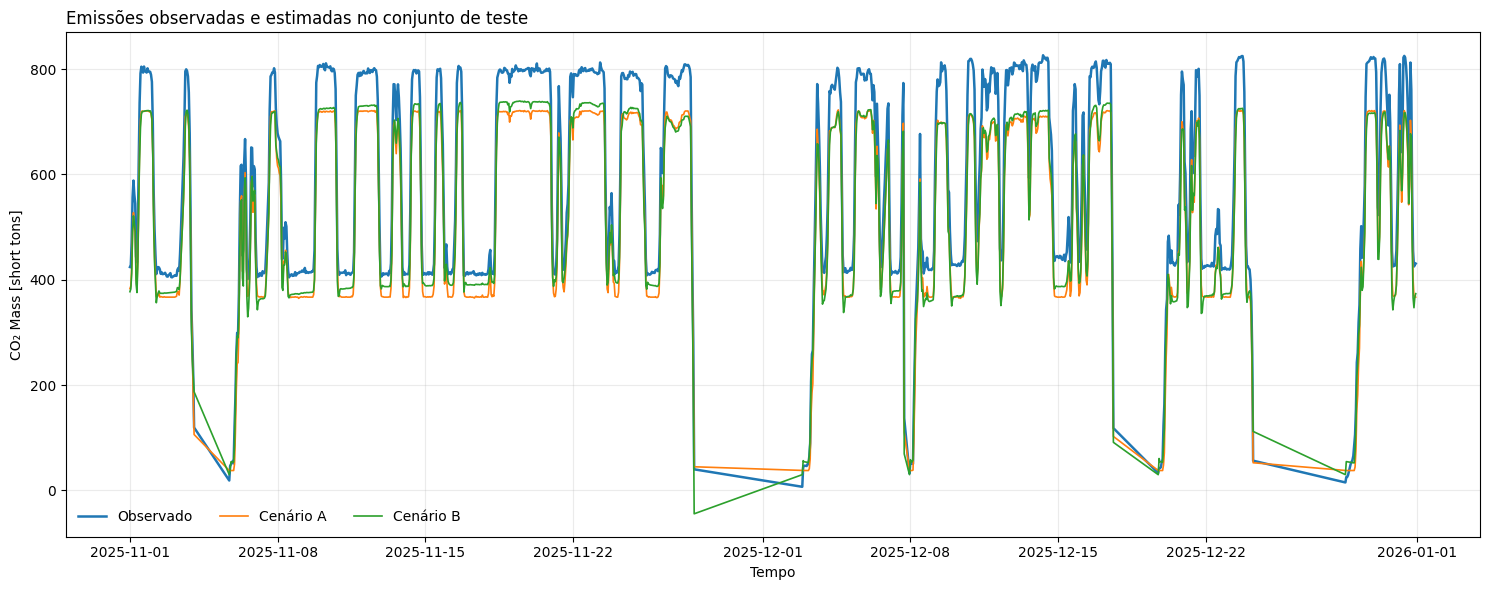

Figura salva em: /content/drive/MyDrive/co2-cems-thermal-modeling/outputs/figures/03A_observado_vs_previsto.png


In [12]:
# ============================================================
# CÉLULA 12 — OBSERVADO × PREVISTO
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Comparar visualmente a série real de emissões com as
# estimativas dos Cenários A e B.
#
# As métricas resumem o desempenho em números.
#
# Este gráfico permite verificar:
#
#   - se os modelos acompanham a tendência temporal;
#   - períodos de subestimação;
#   - períodos de superestimação;
#   - diferenças visuais entre A e B.
# ============================================================


# ============================================================
# 1. CRIAR FIGURA
# ============================================================

fig, ax = plt.subplots(
    figsize=(15, 6)
)


# Série observada.

ax.plot(

    test_data[
        "timestamp"
    ],

    y_true,

    label="Observado",

    linewidth=1.8

)


# Previsão do modelo baseado apenas na carga.

ax.plot(

    test_data[
        "timestamp"
    ],

    pred_A,

    label="Cenário A",

    linewidth=1.2

)


# Previsão do modelo enriquecido com trajetória.

ax.plot(

    test_data[
        "timestamp"
    ],

    pred_B,

    label="Cenário B",

    linewidth=1.2

)


# ============================================================
# 2. FORMATAÇÃO
# ============================================================

ax.set_title(
    "Emissões observadas e estimadas no conjunto de teste",
    loc="left"
)

ax.set_xlabel(
    "Tempo"
)

ax.set_ylabel(
    "CO₂ Mass [short tons]"
)

ax.grid(
    alpha=0.25
)

ax.legend(
    frameon=False,
    ncol=3
)

fig.tight_layout()


# ============================================================
# 3. SALVAR FIGURA
# ============================================================

OBSERVED_PREDICTED_PATH = (
    FIGURES
    /
    "03A_observado_vs_previsto.png"
)


fig.savefig(
    OBSERVED_PREDICTED_PATH,
    dpi=220,
    bbox_inches="tight"
)


plt.show()


print(
    "Figura salva em:",
    OBSERVED_PREDICTED_PATH
)

In [13]:
# ============================================================
# CÉLULA 13 — SALVAR MODELOS E SCALERS
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Persistir os modelos treinados e os objetos utilizados na
# normalização.
#
# Isso permite futuramente:
#
#   - carregar o modelo sem treiná-lo novamente;
#   - reproduzir previsões;
#   - comparar novas versões;
#   - utilizar exatamente a mesma transformação dos dados.
#
#
# IMPORTANTE
# ------------------------------------------------------------
# Salvar apenas o modelo não é suficiente.
#
# Para utilizá-lo corretamente também precisamos preservar os
# scalers usados durante o treinamento.
# ============================================================


# ============================================================
# 1. CAMINHOS DOS MODELOS
# ============================================================

MODEL_A_PATH = (
    MODELS
    /
    "03A_mlp_cenario_A.keras"
)

MODEL_B_PATH = (
    MODELS
    /
    "03A_mlp_cenario_B.keras"
)


# ============================================================
# 2. SALVAR AS REDES
# ============================================================

model_A.save(
    MODEL_A_PATH
)

model_B.save(
    MODEL_B_PATH
)


# ============================================================
# 3. SALVAR OS SCALERS
# ============================================================

joblib.dump(

    scaler_X_A,

    MODELS
    /
    "03A_scaler_X_A.joblib"

)


joblib.dump(

    scaler_X_B,

    MODELS
    /
    "03A_scaler_X_B.joblib"

)


joblib.dump(

    scaler_y,

    MODELS
    /
    "03A_scaler_y.joblib"

)


# ============================================================
# 4. CONFIRMAÇÃO
# ============================================================

print(
    "Modelo A:",
    MODEL_A_PATH
)

print(
    "Modelo B:",
    MODEL_B_PATH
)

print(
    "Scalers salvos em:",
    MODELS
)

Modelo A: /content/drive/MyDrive/co2-cems-thermal-modeling/outputs/models/03A_mlp_cenario_A.keras
Modelo B: /content/drive/MyDrive/co2-cems-thermal-modeling/outputs/models/03A_mlp_cenario_B.keras
Scalers salvos em: /content/drive/MyDrive/co2-cems-thermal-modeling/outputs/models


In [14]:
# ============================================================
# CÉLULA 14 — GERAR RELATÓRIO
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Consolidar automaticamente os principais elementos do
# experimento em um relatório Markdown.
#
# O relatório registra:
#
#   - unidade analisada;
#   - pergunta experimental;
#   - cenários;
#   - divisão temporal;
#   - arquitetura;
#   - métricas;
#   - análise por regime operacional;
#   - artefatos produzidos.
#
#
# VANTAGEM
# ------------------------------------------------------------
# Os números são preenchidos diretamente pelas variáveis
# calculadas no notebook.
#
# Isso reduz o risco de copiar manualmente um valor incorreto
# para a documentação.
# ============================================================

# ============================================================
# FUNDAMENTAÇÃO METODOLÓGICA — RELATÓRIO REPRODUTÍVEL COM FUNDAMENTAÇÃO TEÓRICA
# ------------------------------------------------------------
# O relatório reúne resultados numéricos, artefatos produzidos e
# fundamentos teóricos das técnicas de modelagem e avaliação.
# As limitações descritas devem corresponder ao protocolo
# experimental efetivamente aplicado.
# ============================================================




# ============================================================
# 1. TRANSFORMAR A TABELA DE CONTEXTOS EM MARKDOWN
# ============================================================

context_markdown = (

    context_results
    .round(3)
    .to_markdown(
        index=False
    )

)


# ============================================================
# 2. CONSTRUIR O TEXTO DO RELATÓRIO
# ============================================================
#
# O prefixo f permite inserir diretamente valores das variáveis
# Python dentro do texto.
# ============================================================

report = f"""
# Relatório — Notebook 3A

## 1. Unidade analisada

**Unidade:** {selected_unit['facility_name']} — Unit {selected_unit['unit_id']}
**Facility ID:** {selected_unit['facility_id']}
**Ano:** {selected_unit['year']}

## 2. Pergunta experimental

Em que medida a inclusão de informações sobre estados, memória e trajetória operacional melhora a estimação das emissões horárias de CO₂ em relação ao uso apenas da carga instantânea?

## 3. Cenários

**Cenário A:** carga instantânea, P(t).
**Cenário B:** carga atual + memória e trajetória operacional.

## 4. Divisão temporal

- Treino: {train_data['timestamp'].min()} → {train_data['timestamp'].max()} — **{len(train_data):,} observações**
- Validação: {validation_data['timestamp'].min()} → {validation_data['timestamp'].max()} — **{len(validation_data):,} observações**
- Teste: {test_data['timestamp'].min()} → {test_data['timestamp'].max()} — **{len(test_data):,} observações**

## 5. Arquitetura

**MLP: entrada → Dense(64, ReLU) → Dense(32, ReLU) → Dense(1, linear)**

- Adam, learning rate = {LEARNING_RATE}
- batch size = {BATCH_SIZE}
- máximo de épocas = {MAX_EPOCHS}
- EarlyStopping patience = {PATIENCE}
- melhor época A = {best_epoch_A}
- melhor época B = {best_epoch_B}

## 6. Resultados no teste

| Cenário | MAE | RMSE | R² |
|---|---:|---:|---:|
| A — carga instantânea | {metrics_A['MAE']:.4f} | {metrics_A['RMSE']:.4f} | {metrics_A['R2']:.4f} |
| B — carga + trajetória | {metrics_B['MAE']:.4f} | {metrics_B['RMSE']:.4f} | {metrics_B['R2']:.4f} |

### Ganho do Cenário B

- redução de MAE: **{mae_gain:+.2f}%**
- redução de RMSE: **{rmse_gain:+.2f}%**
- variação de R²: **{delta_r2:+.4f}**

## 7. Análise por contexto operacional

Limiar de rampa intensa: **|ΔP| ≥ {RAMP_THRESHOLD:.2f} MW/h**, definido pelo P90 do treino.

{context_markdown}

## 8. Interpretação metodológica

A hipótese deve ser avaliada pelo desempenho fora da amostra. Melhora apenas no treino não constitui evidência suficiente.

O Cenário B será considerado superior se apresentar ganho consistente no conjunto de teste, especialmente redução de MAE e RMSE e, idealmente, aumento de R².

A análise por contexto verifica se a informação de trajetória é particularmente útil durante startups e rampas intensas.

## 9. Artefatos gerados

### Tabelas
- 03A_divisao_temporal.csv
- 03A_comparacao_modelos.csv
- 03A_previsoes_teste.csv
- 03A_comparacao_contextos.csv

### Figuras
- 03A_curvas_validacao.png
- 03A_observado_vs_previsto.png

### Modelos
- 03A_mlp_cenario_A.keras
- 03A_mlp_cenario_B.keras
- 03A_scaler_X_A.joblib
- 03A_scaler_X_B.joblib
- 03A_scaler_y.joblib

## 10. Fundamentação metodológica da inteligência artificial

### 10.1. Classificação da técnica de IA

O problema consiste em **aprendizado supervisionado de regressão** (*supervised regression*), pois se estima uma variável-resposta numérica contínua, a massa horária de CO₂, a partir de exemplos históricos com entradas e alvos conhecidos. A técnica utilizada é uma **rede neural artificial feedforward** (*feedforward artificial neural network*), especificamente um **Perceptron Multicamadas** (*Multilayer Perceptron, MLP*).

A hierarquia conceitual é: **Inteligência Artificial → Machine Learning → Aprendizado Supervisionado → Regressão → Redes Neurais Artificiais → Redes Feedforward → MLP**.

### 10.2. Arquitetura e funcionamento da MLP

Os dois cenários usam a mesma configuração de camadas ocultas: **Dense(64, ReLU) → Dense(32, ReLU) → Dense(1, linear)**. Camadas *Dense* realizam combinações afins parametrizadas; a ativação *ReLU* introduz não linearidade; a saída linear é compatível com um alvo contínuo. O Cenário A usa uma variável de entrada, enquanto B usa sete; consequentemente, o número total de parâmetros treináveis difere entre cenários.

### 10.3. Retropropagação e otimização

O treinamento minimiza o **erro quadrático médio (Mean Squared Error, MSE)**. O cálculo dos gradientes é realizado por **retropropagação do erro (*backpropagation*) internamente pelo TensorFlow/Keras**, sem implementação manual desse algoritmo neste notebook. O **otimizador Adam (*Adam optimizer*)** emprega os gradientes para atualizar os parâmetros. O **EarlyStopping** monitora `val_loss` e, com `restore_best_weights=True`, recupera os pesos correspondentes à melhor época de validação; isso limita treinamento desnecessário e pode reduzir sobreajuste, sem garantir sua eliminação.

### 10.4. Normalização sem vazamento de dados

A técnica aplicada é a **normalização Min–Max (*min-max scaling*)**. Os parâmetros de escala são ajustados exclusivamente no conjunto de treino (`fit_transform`) e aplicados sem novo ajuste à validação e ao teste (`transform`). Há transformações separadas para as entradas de A, para as entradas de B e para o alvo. As métricas de erro são calculadas após retorno das previsões à unidade original do CO₂. Valores fora da amplitude observada no treino podem ser transformados para fora do intervalo de zero a um.

### 10.5. Divisão temporal e avaliação fora da amostra

A separação de janeiro a setembro para treino, outubro para validação e novembro a dezembro para teste é denominada **temporal holdout**, uma partição cronológica fixa. A validação apoia a escolha da época por EarlyStopping e o teste permanece reservado para a avaliação final **fora da amostra (*out-of-sample evaluation*)**. Este protocolo não corresponde a divisão aleatória nem a validação cruzada temporal *walk-forward*.

### 10.6. Comparação controlada dos conjuntos de variáveis

O desenho A versus B é uma **comparação controlada de conjuntos de features (*controlled feature-set comparison*) com lógica de ablação aditiva** (*feature ablation logic*): o Cenário A usa apenas carga instantânea; o B mantém essa entrada e adiciona memória e trajetória operacional. São mantidos os mesmos períodos, a configuração das camadas ocultas e as condições básicas de treinamento. Como o número de entradas e parâmetros aumenta em B, a comparação não isola perfeitamente todos os efeitos de capacidade, tampouco constitui prova causal. A conclusão empírica é condicionada aos resultados observados no teste.

### 10.7. Técnicas de modelagem e avaliação utilizadas

| Etapa | Técnica explicitada | Aplicação efetiva |
|---|---|---|
| Formulação | Aprendizado supervisionado de regressão | Estimar massa horária de CO₂ |
| Modelo de IA | Feedforward ANN / MLP | Rede densa com duas camadas ocultas |
| Treinamento | Backpropagation e Adam | Gradientes internos ao TensorFlow/Keras; atualização de pesos por Adam |
| Função objetivo | Mean Squared Error, MSE | Perda de treinamento e validação |
| Controle de treinamento | EarlyStopping | Recuperação dos pesos da melhor época de validação |
| Pré-processamento | Train-only min-max scaling | Ajuste dos scalers somente no treino |
| Divisão da amostra | Temporal holdout | Treino, validação e teste cronológicos |
| Comparação | Controlled feature-set comparison | A como baseline e B com trajetória operacional |
| Avaliação | Temporal out-of-sample evaluation | MAE, RMSE e R² no conjunto de teste |

**Delimitação:** esta seção nomeia procedimentos já presentes no código; não afirma a execução de técnicas adicionais como *walk-forward validation*, otimização de hiperparâmetros ou teste formal de significância. A comparação deve ser interpretada conforme as métricas e a análise por contexto efetivamente calculadas.
"""


# ============================================================
# 3. EXIBIR O RELATÓRIO DENTRO DO NOTEBOOK
# ============================================================

display(
    Markdown(
        report
    )
)


# ============================================================
# 4. SALVAR O RELATÓRIO NO DRIVE
# ============================================================

REPORT_PATH = (
    REPORTS
    /
    "relatorio_modelagem_preditiva_3A.md"
)


with open(
    REPORT_PATH,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        report
    )


print(
    "Relatório salvo em:",
    REPORT_PATH
)


# Relatório — Notebook 3A

## 1. Unidade analisada

**Unidade:** Iatan — Unit 2
**Facility ID:** 6065
**Ano:** 2025

## 2. Pergunta experimental

Em que medida a inclusão de informações sobre estados, memória e trajetória operacional melhora a estimação das emissões horárias de CO₂ em relação ao uso apenas da carga instantânea?

## 3. Cenários

**Cenário A:** carga instantânea, P(t).
**Cenário B:** carga atual + memória e trajetória operacional.

## 4. Divisão temporal

- Treino: 2025-01-01 16:00:00 → 2025-09-30 23:00:00 — **4,894 observações**
- Validação: 2025-10-01 00:00:00 → 2025-10-31 23:00:00 — **211 observações**
- Teste: 2025-11-01 00:00:00 → 2025-12-31 23:00:00 — **1,144 observações**

## 5. Arquitetura

**MLP: entrada → Dense(64, ReLU) → Dense(32, ReLU) → Dense(1, linear)**

- Adam, learning rate = 0.001
- batch size = 64
- máximo de épocas = 500
- EarlyStopping patience = 30
- melhor época A = 24
- melhor época B = 38

## 6. Resultados no teste

| Cenário | MAE | RMSE | R² |
|---|---:|---:|---:|
| A — carga instantânea | 67.2508 | 70.9010 | 0.8779 |
| B — carga + trajetória | 61.6102 | 67.0401 | 0.8908 |

### Ganho do Cenário B

- redução de MAE: **+8.39%**
- redução de RMSE: **+5.45%**
- variação de R²: **+0.0129**

## 7. Análise por contexto operacional

Limiar de rampa intensa: **|ΔP| ≥ 130.00 MW/h**, definido pelo P90 do treino.

| contexto                           |    n |   MAE_A |   MAE_B |   reducao_MAE_A_para_B_% |
|:-----------------------------------|-----:|--------:|--------:|-------------------------:|
| Todas as horas de teste            | 1144 |  67.251 |  61.61  |                    8.387 |
| Primeiras 6 h após startup         |   30 |  13.533 |   9.994 |                   26.151 |
| Rampas intensas (>= P90 do treino) |  115 |  65.884 |  75.17  |                  -14.094 |

## 8. Interpretação metodológica

A hipótese deve ser avaliada pelo desempenho fora da amostra. Melhora apenas no treino não constitui evidência suficiente.

O Cenário B será considerado superior se apresentar ganho consistente no conjunto de teste, especialmente redução de MAE e RMSE e, idealmente, aumento de R².

A análise por contexto verifica se a informação de trajetória é particularmente útil durante startups e rampas intensas.

## 9. Artefatos gerados

### Tabelas
- 03A_divisao_temporal.csv
- 03A_comparacao_modelos.csv
- 03A_previsoes_teste.csv
- 03A_comparacao_contextos.csv

### Figuras
- 03A_curvas_validacao.png
- 03A_observado_vs_previsto.png

### Modelos
- 03A_mlp_cenario_A.keras
- 03A_mlp_cenario_B.keras
- 03A_scaler_X_A.joblib
- 03A_scaler_X_B.joblib
- 03A_scaler_y.joblib

## 10. Fundamentação metodológica da inteligência artificial

### 10.1. Classificação da técnica de IA

O problema consiste em **aprendizado supervisionado de regressão** (*supervised regression*), pois se estima uma variável-resposta numérica contínua, a massa horária de CO₂, a partir de exemplos históricos com entradas e alvos conhecidos. A técnica utilizada é uma **rede neural artificial feedforward** (*feedforward artificial neural network*), especificamente um **Perceptron Multicamadas** (*Multilayer Perceptron, MLP*).

A hierarquia conceitual é: **Inteligência Artificial → Machine Learning → Aprendizado Supervisionado → Regressão → Redes Neurais Artificiais → Redes Feedforward → MLP**.

### 10.2. Arquitetura e funcionamento da MLP

Os dois cenários usam a mesma configuração de camadas ocultas: **Dense(64, ReLU) → Dense(32, ReLU) → Dense(1, linear)**. Camadas *Dense* realizam combinações afins parametrizadas; a ativação *ReLU* introduz não linearidade; a saída linear é compatível com um alvo contínuo. O Cenário A usa uma variável de entrada, enquanto B usa sete; consequentemente, o número total de parâmetros treináveis difere entre cenários.

### 10.3. Retropropagação e otimização

O treinamento minimiza o **erro quadrático médio (Mean Squared Error, MSE)**. O cálculo dos gradientes é realizado por **retropropagação do erro (*backpropagation*) internamente pelo TensorFlow/Keras**, sem implementação manual desse algoritmo neste notebook. O **otimizador Adam (*Adam optimizer*)** emprega os gradientes para atualizar os parâmetros. O **EarlyStopping** monitora `val_loss` e, com `restore_best_weights=True`, recupera os pesos correspondentes à melhor época de validação; isso limita treinamento desnecessário e pode reduzir sobreajuste, sem garantir sua eliminação.

### 10.4. Normalização sem vazamento de dados

A técnica aplicada é a **normalização Min–Max (*min-max scaling*)**. Os parâmetros de escala são ajustados exclusivamente no conjunto de treino (`fit_transform`) e aplicados sem novo ajuste à validação e ao teste (`transform`). Há transformações separadas para as entradas de A, para as entradas de B e para o alvo. As métricas de erro são calculadas após retorno das previsões à unidade original do CO₂. Valores fora da amplitude observada no treino podem ser transformados para fora do intervalo de zero a um.

### 10.5. Divisão temporal e avaliação fora da amostra

A separação de janeiro a setembro para treino, outubro para validação e novembro a dezembro para teste é denominada **temporal holdout**, uma partição cronológica fixa. A validação apoia a escolha da época por EarlyStopping e o teste permanece reservado para a avaliação final **fora da amostra (*out-of-sample evaluation*)**. Este protocolo não corresponde a divisão aleatória nem a validação cruzada temporal *walk-forward*.

### 10.6. Comparação controlada dos conjuntos de variáveis

O desenho A versus B é uma **comparação controlada de conjuntos de features (*controlled feature-set comparison*) com lógica de ablação aditiva** (*feature ablation logic*): o Cenário A usa apenas carga instantânea; o B mantém essa entrada e adiciona memória e trajetória operacional. São mantidos os mesmos períodos, a configuração das camadas ocultas e as condições básicas de treinamento. Como o número de entradas e parâmetros aumenta em B, a comparação não isola perfeitamente todos os efeitos de capacidade, tampouco constitui prova causal. A conclusão empírica é condicionada aos resultados observados no teste.

### 10.7. Técnicas de modelagem e avaliação utilizadas

| Etapa | Técnica explicitada | Aplicação efetiva |
|---|---|---|
| Formulação | Aprendizado supervisionado de regressão | Estimar massa horária de CO₂ |
| Modelo de IA | Feedforward ANN / MLP | Rede densa com duas camadas ocultas |
| Treinamento | Backpropagation e Adam | Gradientes internos ao TensorFlow/Keras; atualização de pesos por Adam |
| Função objetivo | Mean Squared Error, MSE | Perda de treinamento e validação |
| Controle de treinamento | EarlyStopping | Recuperação dos pesos da melhor época de validação |
| Pré-processamento | Train-only min-max scaling | Ajuste dos scalers somente no treino |
| Divisão da amostra | Temporal holdout | Treino, validação e teste cronológicos |
| Comparação | Controlled feature-set comparison | A como baseline e B com trajetória operacional |
| Avaliação | Temporal out-of-sample evaluation | MAE, RMSE e R² no conjunto de teste |

**Delimitação:** esta seção nomeia procedimentos já presentes no código; não afirma a execução de técnicas adicionais como *walk-forward validation*, otimização de hiperparâmetros ou teste formal de significância. A comparação deve ser interpretada conforme as métricas e a análise por contexto efetivamente calculadas.


Relatório salvo em: /content/drive/MyDrive/co2-cems-thermal-modeling/outputs/reports/relatorio_modelagem_preditiva_3A.md


In [15]:
# ============================================================
# CÉLULA 15 — CONCLUSÃO AUTOMÁTICA
# ============================================================
#
# OBJETIVO
# ------------------------------------------------------------
# Produzir uma síntese automática baseada nas três métricas
# principais.
#
# A lógica não determina que B PRECISA ser melhor.
#
# Ela contempla três situações:
#
#   1. B melhora MAE, RMSE e R²;
#
#   2. B melhora MAE e RMSE, mas não necessariamente R²;
#
#   3. B não apresenta melhora consistente.
#
# Assim, um resultado negativo também permanece cientificamente
# válido.
# ============================================================


print("=" * 72)
print("CONCLUSÃO DO NOTEBOOK 3A")
print("=" * 72)


# ============================================================
# SITUAÇÃO 1
# B É MELHOR NAS TRÊS MÉTRICAS
# ============================================================

if (

    metrics_B["MAE"]
    <
    metrics_A["MAE"]

    and

    metrics_B["RMSE"]
    <
    metrics_A["RMSE"]

    and

    metrics_B["R2"]
    >
    metrics_A["R2"]

):

    conclusion = """
O Cenário B apresentou desempenho superior nas três métricas principais do conjunto de teste.

Os resultados fornecem evidência favorável à hipótese de que informações sobre memória e trajetória operacional contribuem para a estimação horária de CO₂ além da carga instantânea.
"""


# ============================================================
# SITUAÇÃO 2
# B REDUZ OS ERROS, MAS O R² NÃO MELHORA
# ============================================================

elif (

    metrics_B["MAE"]
    <
    metrics_A["MAE"]

    and

    metrics_B["RMSE"]
    <
    metrics_A["RMSE"]

):

    conclusion = """
O Cenário B reduziu MAE e RMSE no conjunto de teste.

Há evidência de ganho preditivo com a inclusão de informações operacionais, embora a interpretação deva considerar também o R² e a magnitude prática da diferença.
"""


# ============================================================
# SITUAÇÃO 3
# NÃO HÁ MELHORA CONSISTENTE
# ============================================================

else:

    conclusion = """
O Cenário B não apresentou melhora consistente nas principais métricas do conjunto de teste.

Neste experimento, a inclusão das informações de trajetória não foi suficiente para demonstrar ganho preditivo global em relação ao uso apenas da carga instantânea.

Esse resultado continua sendo cientificamente relevante e deve ser interpretado em conjunto com a análise por contexto operacional.
"""


# ============================================================
# EXIBIR CONCLUSÃO E LOCALIZAÇÃO DOS ARTEFATOS
# ============================================================

print(
    conclusion
)

print(
    "Relatório:",
    REPORT_PATH
)

print(
    "Resultados:",
    RESULTS_PATH
)

print(
    "Previsões:",
    PREDICTIONS_PATH
)

print(
    "Contextos:",
    CONTEXT_RESULTS_PATH
)

print(
    "NOTEBOOK 3A CONCLUÍDO."
)

CONCLUSÃO DO NOTEBOOK 3A

O Cenário B apresentou desempenho superior nas três métricas principais do conjunto de teste.

Os resultados fornecem evidência favorável à hipótese de que informações sobre memória e trajetória operacional contribuem para a estimação horária de CO₂ além da carga instantânea.

Relatório: /content/drive/MyDrive/co2-cems-thermal-modeling/outputs/reports/relatorio_modelagem_preditiva_3A.md
Resultados: /content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A_comparacao_modelos.csv
Previsões: /content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A_previsoes_teste.csv
Contextos: /content/drive/MyDrive/co2-cems-thermal-modeling/outputs/tables/03A_comparacao_contextos.csv
NOTEBOOK 3A CONCLUÍDO.


## Referências

CAWLEY, G. C.; TALBOT, N. L. C. On Over-fitting in Model Selection and Subsequent Selection Bias in Performance Evaluation. **Journal of Machine Learning Research**, *[s. l.]*, v. 11, n. 70, p. 2079-2107, 2010. Disponível em: https://jmlr.org/papers/v11/cawley10a.html. Acesso em: 24 out. 2026.

CERQUEIRA, V.; TORGO, L.; MOZETIČ, I. Evaluating time series forecasting models: an empirical study on performance estimation methods. **Machine Learning**, *[s. l.]*, v. 109, n. 11, p. 1997-2028, 2020. DOI: https://doi.org/10.1007/s10994-020-05910-7. Disponível em: https://link.springer.com/article/10.1007/s10994-020-05910-7. Acesso em: 24 out. 2026.

GLOROT, X.; BORDES, A.; BENGIO, Y. Deep Sparse Rectifier Neural Networks. *In:* INTERNATIONAL CONFERENCE ON ARTIFICIAL INTELLIGENCE AND STATISTICS, 14., 2011, Fort Lauderdale. **Proceedings [...]**. *[S. l.]*: PMLR, 2011. v. 15, p. 315-323. Disponível em: https://proceedings.mlr.press/v15/glorot11a.html. Acesso em: 24 out. 2026.

HYNDMAN, R. J.; KOEHLER, A. B. Another look at measures of forecast accuracy. **International Journal of Forecasting**, *[s. l.]*, v. 22, n. 4, p. 679-688, 2006. DOI: https://doi.org/10.1016/j.ijforecast.2006.03.001. Disponível em: https://robjhyndman.com/publications/another-look-at-measures-of-forecast-accuracy/. Acesso em: 24 out. 2026.

KINGMA, D. P.; BA, J. **Adam**: A Method for Stochastic Optimization. *[S. l.: s. n.]*, 2015. Trabalho apresentado na 3rd International Conference on Learning Representations, San Diego, 2015. Disponível em: https://arxiv.org/abs/1412.6980. Acesso em: 24 out. 2026.


RUMELHART, D. E.; HINTON, G. E.; WILLIAMS, R. J. Learning representations by back-propagating errors. **Nature**, *[s. l.]*, v. 323, n. 6088, p. 533-536, 1986. DOI: https://doi.org/10.1038/323533a0. Disponível em: https://www.cs.toronto.edu/~hinton/absps/naturebp.pdf. Acesso em: 24 out. 2026.

SCIKIT-LEARN. **User Guide**. Version 1.8.0. *[S. l.]*: The scikit-learn developers, [2025]. Disponível em: https://scikit-learn.org/1.8/user_guide.html. Acesso em: 24 out. 2026.

GU, J.; SWARD, J. A.; ZHANG, K. M. Predicting power plant emissions using public data and machine learning. **Environmental Science: Advances**, *[s. l.]*, v. 2, p. 1696-1707, 2023. DOI: https://doi.org/10.1039/D3VA00191A. Disponível em: https://pubs.rsc.org/en/content/articlehtml/2023/va/d3va00191a. Acesso em: 29 out. 2026.

SURI, D.; DE CHALENDAR, J.; AZEVEDO, I. M. L. Assessing the real implications for CO₂ as generation from renewables increases. **Nature Communications**, *[s. l.]*, v. 16, art. 7124, 2025. DOI: https://doi.org/10.1038/s41467-025-59800-4. Disponível em: https://www.nature.com/articles/s41467-025-59800-4. Acesso em: 29 out. 2026.

WANG, S.; FANG, B.; ZHANG, J.; XING, S.; WU, J.; XIAO, H. Comparative study of machine learning methods for carbon metering in power generation enterprises. **Scientific Reports**, *[s. l.]*, v. 15, art. 41333, 2025. DOI: https://doi.org/10.1038/s41598-025-25227-6. Disponível em: https://www.nature.com/articles/s41598-025-25227-6. Acesso em: 29 out. 2026.
